# Updating a Model After Change

## Prediction Before Observation

For each evaluation date \(t\), the model available after date \(t-1\) produces

$$
\widehat y_t=f_{t-1}(x_t),
$$

where \(x_t\) contains only lagged returns and trailing summaries known through date \(t-1\). After \(y_t\) is observed, the mistake is

$$
L_t=\mathbf{1}\{\widehat y_t\ne y_t\}.
$$

Here, \(f_{t-1}\) is the fitted classifier before the current outcome is known, \(\widehat y_t\) is its class prediction, and \(L_t\in\{0,1\}\) is the bounded loss. A refit after observing \(y_t\) can affect date \(t+1\) and later, but it cannot alter \(\widehat y_t\).

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("13_regime_adaptation");
using CSV, Printf
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookLogisticLBFGS.jl"))
include(joinpath("..","support","BookMarkovRegression.jl"))
using .BookMarkovRegression
using RiskLabAI.Backtest: prequential_adaptation
using RiskLabAI.Data: symmetric_cusum_filter,cusum_filter_events_dynamic_threshold
using RiskLabAI.Features: pelt_change_points
data_path = dataset_path("fred_nasdaq")
@assert isfile(data_path)
raw = CSV.read(data_path,DataFrame;missingstring=["","."])
data = sort(dropmissing(raw,:NASDAQCOM),:observation_date)
dates = DateTime.(Date.(data.observation_date))
prices = Float64.(data.NASDAQCOM)
daily_returns = vcat(NaN,100log.(prices[2:end]./prices[1:end-1]))
log_index = 100log.(prices)
violet = "#C084FC"
year_dates = DateTime.(Date(1995):Year(5):Date(2025))
year_ticks = (Dates.value.(year_dates),Dates.format.(year_dates,dateformat"yyyy"))
date_limits = Dates.value.((first(dates)-Day(90),last(dates)+Day(90)))
feature_names = ["Previous return (%)","Previous absolute return (%)","Trailing 5 day mean (%)","Trailing 21 day volatility (%)","Trailing 63 day volatility (%)"]
min_samples,window_size = 756,756

function table(frame,name,caption,label="tab:chapter14-"*replace(name,"_"=>"-"))
    save_table(frame,paths,name;caption,label)
    return nothing
end

function rolling_mean(values,window;minimum_count=window)
    return [index<minimum_count ? NaN : mean(values[max(1,index-window+1):index]) for index in eachindex(values)]
end

function prepare_sequential_data()
    positions = collect(65:length(prices))
    features = hcat(daily_returns[positions.-1],abs.(daily_returns[positions.-1]),[mean(daily_returns[index-5:index-1]) for index in positions],[std(daily_returns[index-21:index-1];corrected=false) for index in positions],[std(daily_returns[index-63:index-1];corrected=false) for index in positions])
    threshold = quantile(abs.(daily_returns[positions[1:min_samples]]),.8)
    targets = Int.(abs.(daily_returns[positions]).>threshold)
    frame = DataFrame(position=positions,date=dates[positions],daily_return=daily_returns[positions],target=targets)
    for (column,name) in enumerate(feature_names)
        frame[!,name] = features[:,column]
    end
    @assert all(isfinite,features)
    @assert allunique(Tuple.(eachrow(features)))
    return frame,features,targets,threshold
end

function run_policy(features,targets;policy=:adaptive,delta=.01,interval=252)
    positions = Dict(Tuple(row)=>index for (index,row) in enumerate(eachrow(features)))
    models = NamedTuple[]
    scores = fill(NaN,length(targets))
    function fitted(training_x,training_y)
        model = BookLogisticLBFGS.fit_logistic(training_x,training_y;C=1.,class_weight=:balanced,standardize=true,tol=1e-4,max_iter=1000)
        @assert model.converged
        push!(models,(first_position=positions[Tuple(training_x[1,:])],last_position=positions[Tuple(training_x[end,:])],model=model))
        return model
    end
    function predicted(model,row)
        scores[positions[Tuple(row[1,:])]] = only(BookEstimators.decision_function(model,row))
        return BookEstimators.predict(model,row)
    end
    if policy==:adaptive
        result = prequential_adaptation(features,Float64.(targets),nothing;fit_estimator=(_,x,y)->fitted(x,y),predict_estimator=predicted,clone_estimator=identity,loss_function=(actual,prediction)->Float64(actual!=prediction),window_size,min_samples,delta)
        return (;result...,models,scores)
    end
    predictions,losses = fill(NaN,length(targets)),fill(NaN,length(targets))
    refit_indices = [min_samples]
    model = fitted(features[1:min_samples,:],targets[1:min_samples])
    for index in min_samples+1:length(targets)
        predictions[index] = only(predicted(model,features[index:index,:]))
        losses[index] = Float64(predictions[index]!=targets[index])
        if policy==:periodic && (index-min_samples)%interval==0
            model = fitted(features[max(1,index-window_size+1):index,:],targets[max(1,index-window_size+1):index])
            push!(refit_indices,index)
        end
    end
    return (;predictions,losses,refit_indices,alarm_indices=Int[],models,scores)
end

function save_policy(result,name)
    observations = DataFrame(position=1:length(result.predictions),prediction=result.predictions,loss=result.losses,score=result.scores,refit=in.(1:length(result.predictions),Ref(result.refit_indices)),alarm=in.(1:length(result.predictions),Ref(result.alarm_indices)))
    save_data(observations,paths,name*"_observations")
    rows = NamedTuple[]
    for (number,record) in enumerate(result.models)
        model = record.model
        base = (fit=number,first_position=record.first_position,last_position=record.last_position,intercept=model.intercept,objective=model.objective,gradient_norm=model.gradient_norm,converged=model.converged,iterations=model.iterations)
        values = (; (Symbol("coefficient_",i)=>model.coefficients[i] for i in 1:5)...,(Symbol("center_",i)=>model.scaler.center[i] for i in 1:5)...,(Symbol("scale_",i)=>model.scaler.scale[i] for i in 1:5)...)
        push!(rows,merge(base,values))
    end
    save_data(DataFrame(rows),paths,name*"_fits")
    return nothing
end

function event_marks!(figure,event_dates,position,color)
    for date in event_dates
        plot!(figure,fill(Dates.value(date),2),[position-.28,position+.28];color,linewidth=.9,label=false)
    end
    return figure
end


event_marks! (generic function with 1 method)

Row,Policy,Refit rule,Rows used at a refit,Future information used
,String,String,Int64,String
1,Static,No refit after the initial sample,756,No
2,Fixed schedule,Every 252 observed evaluation rows,756,No
3,ADWIN alarm,After an alarm in the bounded loss stream,756,No


Row,Policy,Evaluation observations,Mistakes,Mean loss,Accuracy,Predicted large moves,Actual large moves,Large move precision,Large move recall,Refits after initialization
,String,Int64,Int64,Float64,Float64,Int64,Int64,Float64,Float64,Int64
1,Static,7235,3018,0.417139,0.582861,5034,2742,0.472586,0.867615,0
2,Fixed schedule,7235,2435,0.336558,0.663442,2841,2742,0.55403,0.574034,28
3,ADWIN alarm,7235,2394,0.330891,0.669109,3080,2742,0.556494,0.625091,9


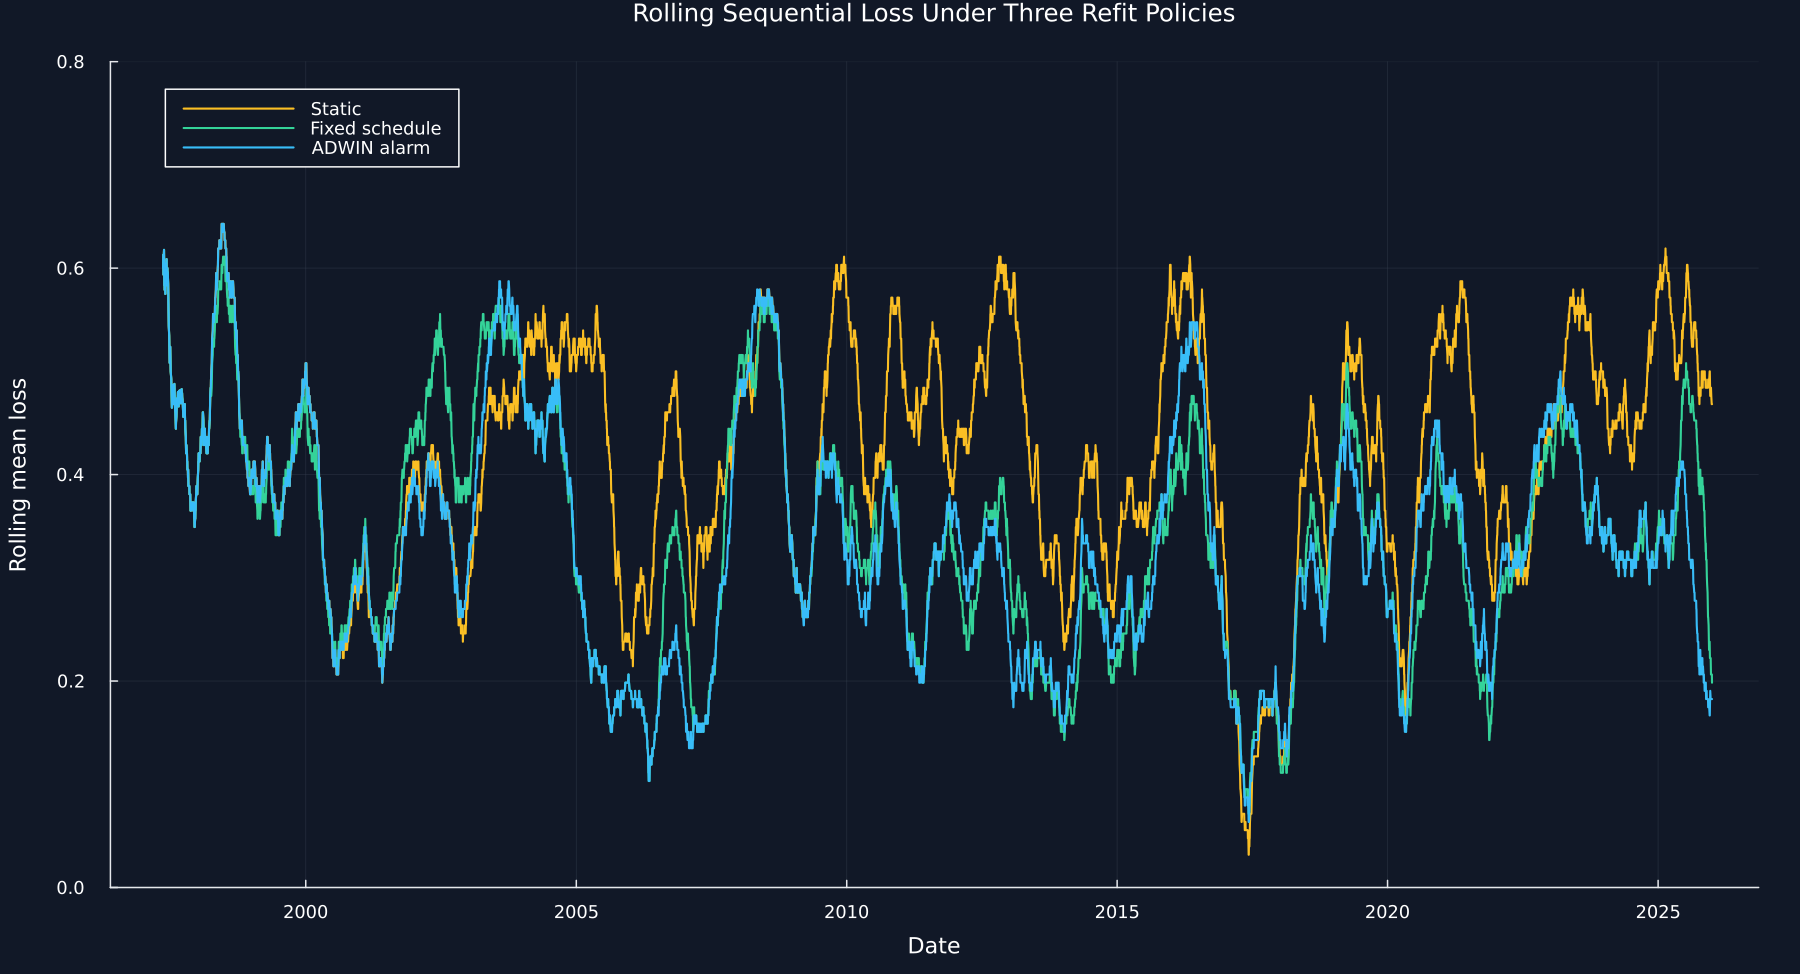

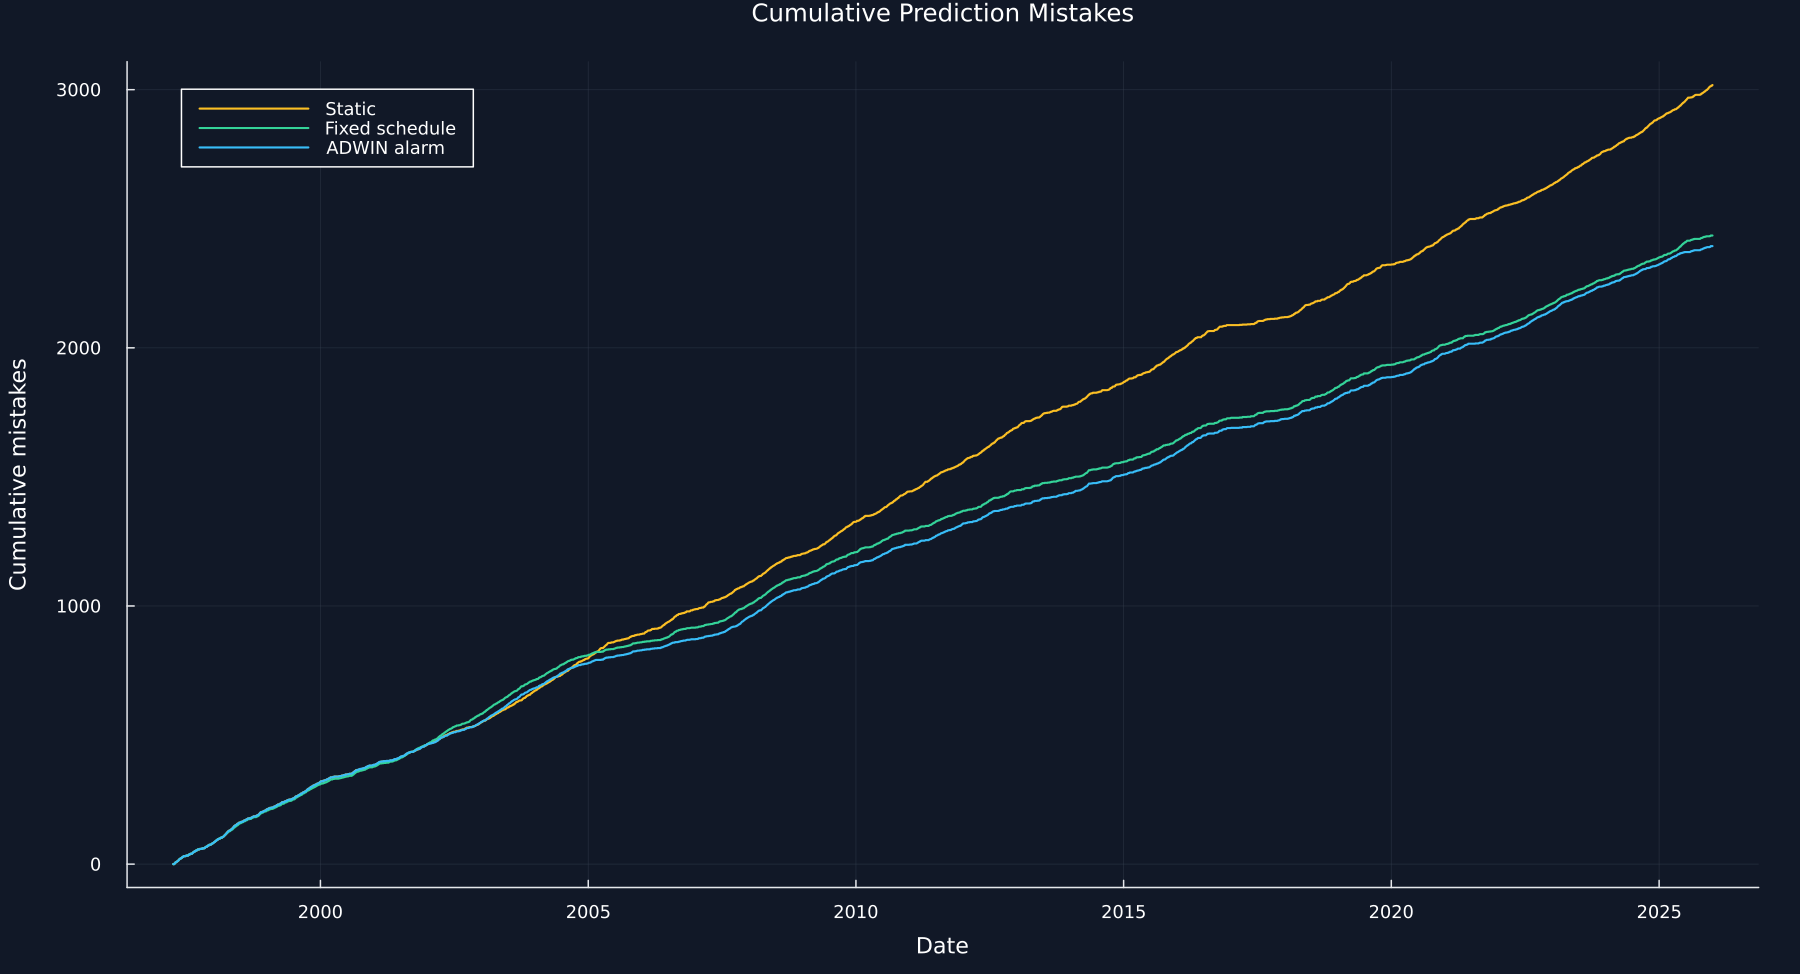

In [2]:
model_frame,features,targets,large_move_threshold = prepare_sequential_data()
static = run_policy(features,targets;policy=:static)
periodic = run_policy(features,targets;policy=:periodic,interval=252)
adaptive = run_policy(features,targets;delta=.01)
evaluation_dates = model_frame.date[min_samples+1:end]
evaluation_years = filter(date->first(evaluation_dates)<=date<=last(evaluation_dates),year_dates)
evaluation_ticks = (Dates.value.(evaluation_years),Dates.format.(evaluation_years,dateformat"yyyy"))
policy_names = ["Static","Fixed schedule","ADWIN alarm"]
policy_outputs = [static,periodic,adaptive]
policy_colors = [palette.amber,palette.green,palette.cyan]
for (name,result) in zip(["policy_static","policy_periodic","policy_adwin"],policy_outputs)
    save_policy(result,name)
end
table(DataFrame("Policy" => ["Static", "Fixed schedule", "ADWIN alarm"],"Refit rule" => ["No refit after the initial sample", "Every 252 observed evaluation rows", "After an alarm in the bounded loss stream"],"Rows used at a refit" => [756, 756, 756],"Future information used" => ["No", "No", "No"]),"policy_definitions","Three predeclared refit policies compared on the same sequential task.","tab:chapter14-policy-definitions")
actual = targets[min_samples+1:end]
policy_rows = NamedTuple[]
policy_data = DataFrame(date=evaluation_dates,actual=actual)
for (name,result) in zip(policy_names,policy_outputs)
    predictions,losses = result.predictions[min_samples+1:end],result.losses[min_samples+1:end]
    true_positive = count((predictions.==1).&(actual.==1))
    predicted_positive,actual_positive = count(==(1),predictions),sum(actual)
    push!(policy_rows,(policy=name,observations=length(losses),mistakes=Int(sum(losses)),mean_loss=mean(losses),accuracy=1-mean(losses),predicted_positive=predicted_positive,actual_positive=actual_positive,precision=true_positive/predicted_positive,recall=true_positive/actual_positive,refits=length(result.refit_indices)-1))
    policy_data[!,name*" prediction"] = predictions
    policy_data[!,name*" loss"] = losses
    policy_data[!,name*" rolling 126 day mean loss"] = rolling_mean(losses,126;minimum_count=30)
    policy_data[!,name*" cumulative mistakes"] = cumsum(losses)
end
policy_summary = DataFrame(policy_rows)
rename!(policy_summary,["Policy","Evaluation observations","Mistakes","Mean loss","Accuracy","Predicted large moves","Actual large moves","Large move precision","Large move recall","Refits after initialization"])
table(policy_summary,"policy_summary","Sequential loss and classification summaries for the three fixed policies.")
save_data(policy_data,paths,"policy_observations");
for (name,suffix,title,ylabel) in [("rolling_policy_loss"," rolling 126 day mean loss","Rolling Sequential Loss Under Three Refit Policies","Rolling mean loss"),("cumulative_mistakes"," cumulative mistakes","Cumulative Prediction Mistakes","Cumulative mistakes")]
    figure = plot(;xlabel="Date",ylabel,title,xticks=evaluation_ticks,legend=:topleft,size=(1200,650))
    for (policy,color) in zip(policy_names,policy_colors)
        plot!(figure,evaluation_dates,policy_data[!,policy*suffix];color,linewidth=1.4,label=policy)
    end
    name=="rolling_policy_loss" && plot!(figure;ylims=(0,.8))
    save_data(select(policy_data,vcat(["date"],policy_names.*suffix)),paths,name)
    save_figure(figure,paths,name)
end


## Comparing three adaptation schedules

For a trailing window of \(w\) observed losses, the rolling mean loss is

$$
\overline L_t^{(w)}
=\frac{1}{w}\sum_{s=t-w+1}^{t}L_s.
$$

Here, \(w=126\) trading observations, \(L_s\) is the zero or one mistake on date \(s\), and \(\overline L_t^{(w)}\) is the recent mistake rate. The static policy never changes its initial fit. The fixed schedule refits every 252 observed evaluation rows. The alarm policy refits only after ADWIN signals a change. All three policies use the same features, target, initial sample, estimator, and loss.

Row,Calendar block,Policy,Observations,Mistakes,Mean loss
,String,String,Int64,Int64,Float64
1,1997 to 2001,Static,1195,464,0.388285
2,1997 to 2001,Fixed schedule,1195,465,0.389121
3,1997 to 2001,ADWIN alarm,1195,465,0.389121
4,2002 to 2006,Static,1259,523,0.415409
5,2002 to 2006,Fixed schedule,1259,451,0.358221
6,2002 to 2006,ADWIN alarm,1259,406,0.322478
7,2007 to 2011,Static,1260,569,0.451587
8,2007 to 2011,Fixed schedule,1260,452,0.35873
9,2007 to 2011,ADWIN alarm,1260,448,0.355556


Row,Policy,Refit number,Observation date,Reason
,String,Int64,DateTime,String
1,Static,1,1997-04-01T00:00:00,Initial sample
2,Fixed schedule,1,1997-04-01T00:00:00,Initial sample
3,Fixed schedule,2,1998-03-31T00:00:00,Fixed schedule
4,Fixed schedule,3,1999-03-31T00:00:00,Fixed schedule
5,Fixed schedule,4,2000-03-29T00:00:00,Fixed schedule
6,Fixed schedule,5,2001-03-29T00:00:00,Fixed schedule
7,Fixed schedule,6,2002-04-05T00:00:00,Fixed schedule
8,Fixed schedule,7,2003-04-04T00:00:00,Fixed schedule
9,Fixed schedule,8,2004-04-05T00:00:00,Fixed schedule


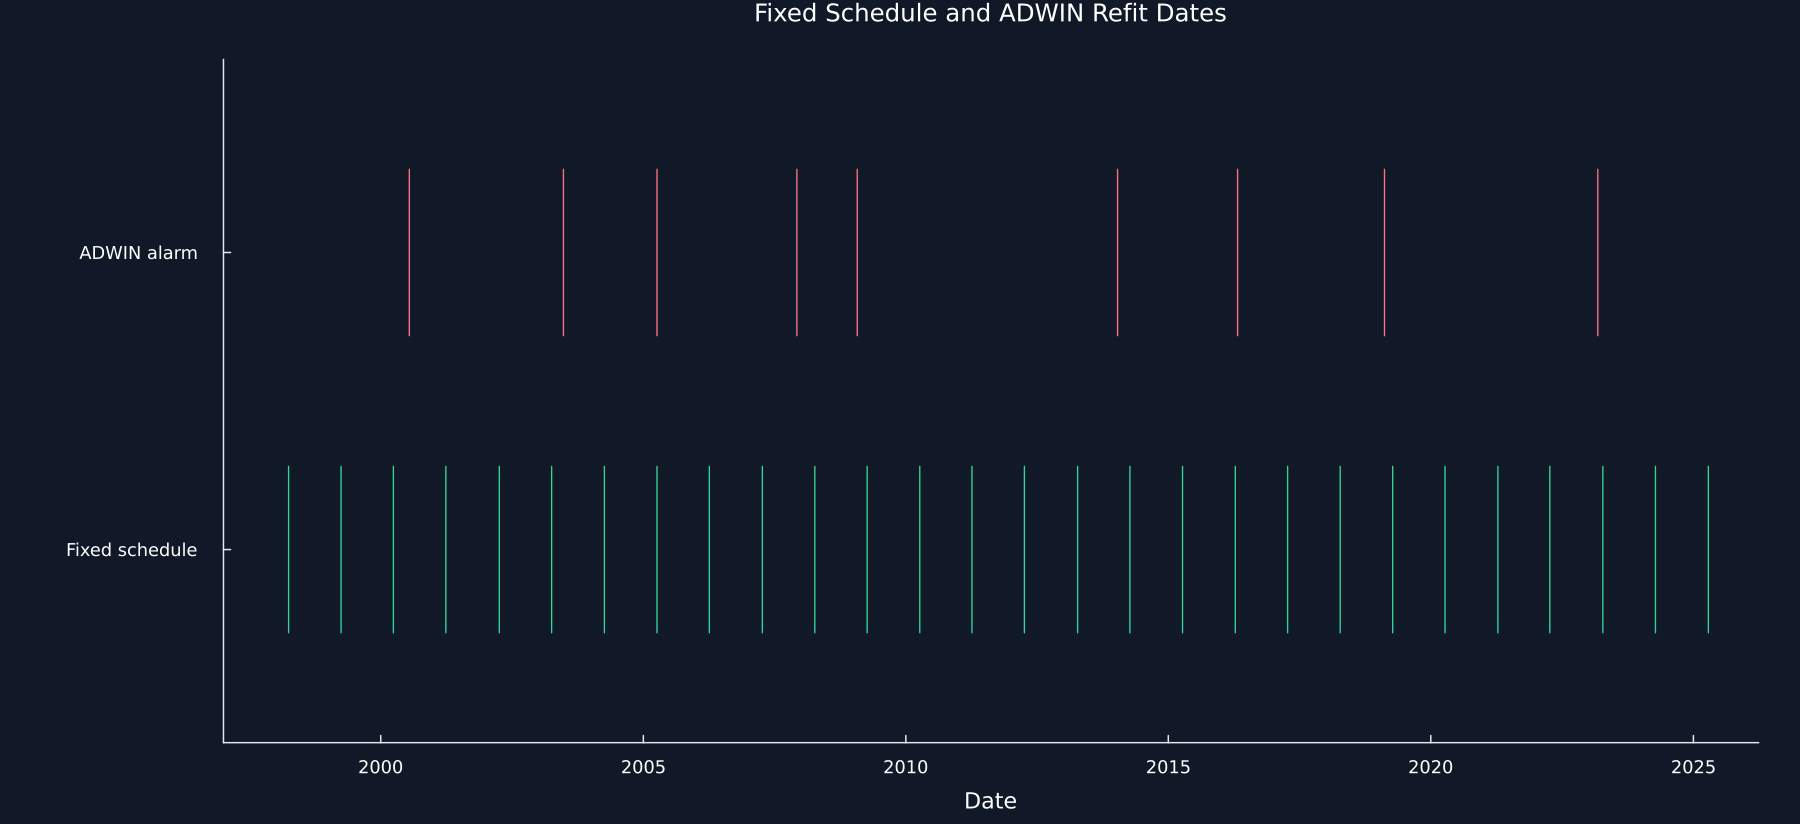

Row,Check,Result
,String,Bool
1,All policies evaluate the same number of dates,true
2,All evaluation predictions are finite,true
3,All losses are zero or one,true
4,Fixed schedule gaps are 252 observations,true
5,ADWIN alarm dates equal later refit dates,true
6,Initial fit ends before the first evaluation date,true


In [3]:
block_edges = [1996,2001,2006,2011,2016,2021,2025]
block_labels = ["1997 to 2001","2002 to 2006","2007 to 2011","2012 to 2016","2017 to 2021","2022 to 2025"]
block_rows = NamedTuple[]
for (index,label) in enumerate(block_labels)
    selected = (block_edges[index].<year.(evaluation_dates)).&(year.(evaluation_dates).<=block_edges[index+1])
    for name in policy_names
        losses = policy_data[selected,name*" loss"]
        push!(block_rows,(block=label,policy=name,observations=length(losses),mistakes=Int(sum(losses)),mean_loss=mean(losses)))
    end
end
block_table = DataFrame(block_rows)
rename!(block_table,["Calendar block","Policy","Observations","Mistakes","Mean loss"])
table(block_table,"policy_calendar_blocks","Sequential loss by fixed calendar block and refit policy.")
refit_rows = NamedTuple[]
for (name,result) in zip(policy_names,policy_outputs), (number,index) in enumerate(result.refit_indices)
    push!(refit_rows,(policy=name,number=number,date=model_frame.date[index],reason=number==1 ? "Initial sample" : name=="Fixed schedule" ? "Fixed schedule" : "ADWIN alarm"))
end
refit_table = DataFrame(refit_rows)
rename!(refit_table,["Policy","Refit number","Observation date","Reason"])
table(refit_table,"policy_refit_dates","Dates at which each policy fits or refits its classifier.")
refit_figure = refit_table[refit_table[!,"Refit number"].>1,["Policy","Observation date","Reason"]]
save_data(refit_figure,paths,"policy_refit_timeline");
p1 = plot(;xlabel="Date",title="Fixed Schedule and ADWIN Refit Dates",yticks=(0:1,["Fixed schedule","ADWIN alarm"]),ylims=(-.65,1.65),xlims=Dates.value.((first(evaluation_dates)-Day(90),last(evaluation_dates)+Day(90))),xticks=evaluation_ticks,grid=false,size=(1200,550),left_margin=10Plots.mm)
for (position,(name,color)) in enumerate(zip(policy_names[2:3],[palette.green,palette.rose]))
    event_marks!(p1,refit_figure[refit_figure.Policy.==name,"Observation date"],position-1,color)
end
save_figure(p1,paths,"policy_refit_timeline")
order_results = [length(unique(length(result.losses)-min_samples for result in policy_outputs))==1,all(result->all(isfinite,result.predictions[min_samples+1:end]),policy_outputs),all(result->all(in((0.,1.)),result.losses[min_samples+1:end]),policy_outputs),all(diff(periodic.refit_indices).==252),adaptive.alarm_indices==adaptive.refit_indices[2:end],model_frame.date[min_samples]<first(evaluation_dates)]
table(DataFrame("Check"=>["All policies evaluate the same number of dates","All evaluation predictions are finite","All losses are zero or one","Fixed schedule gaps are 252 observations","ADWIN alarm dates equal later refit dates","Initial fit ends before the first evaluation date"],"Result"=>order_results),"policy_order_checks","Mechanical checks for the common sequential comparison.")
@assert all(order_results)
@assert all([sum(block_table[block_table.Policy.==name,"Observations"])==length(evaluation_dates) for name in policy_names])


## Fixed Sensitivity Comparison

The ADWIN confidence parameter \(\delta\) controls the probability level used by its change test. This notebook keeps \(\delta=0.01\) as the default and reports two predeclared alternatives, \(0.002\) and \(0.05\). Every other feature, target, estimator, initial sample, and rolling refit window remains unchanged. The sensitivity calculation describes how this one setting changes the observed alarms and loss in this sample; it is not used to replace the default after seeing the results.

Row,ADWIN confidence parameter,Alarms,Refits after initialization,Mistakes,Mean loss,Accuracy
,Float64,Int64,Int64,Int64,Float64,Float64
1,0.002,7,7,2583,0.357015,0.642985
2,0.01,9,9,2394,0.330891,0.669109
3,0.05,11,11,2394,0.330891,0.669109


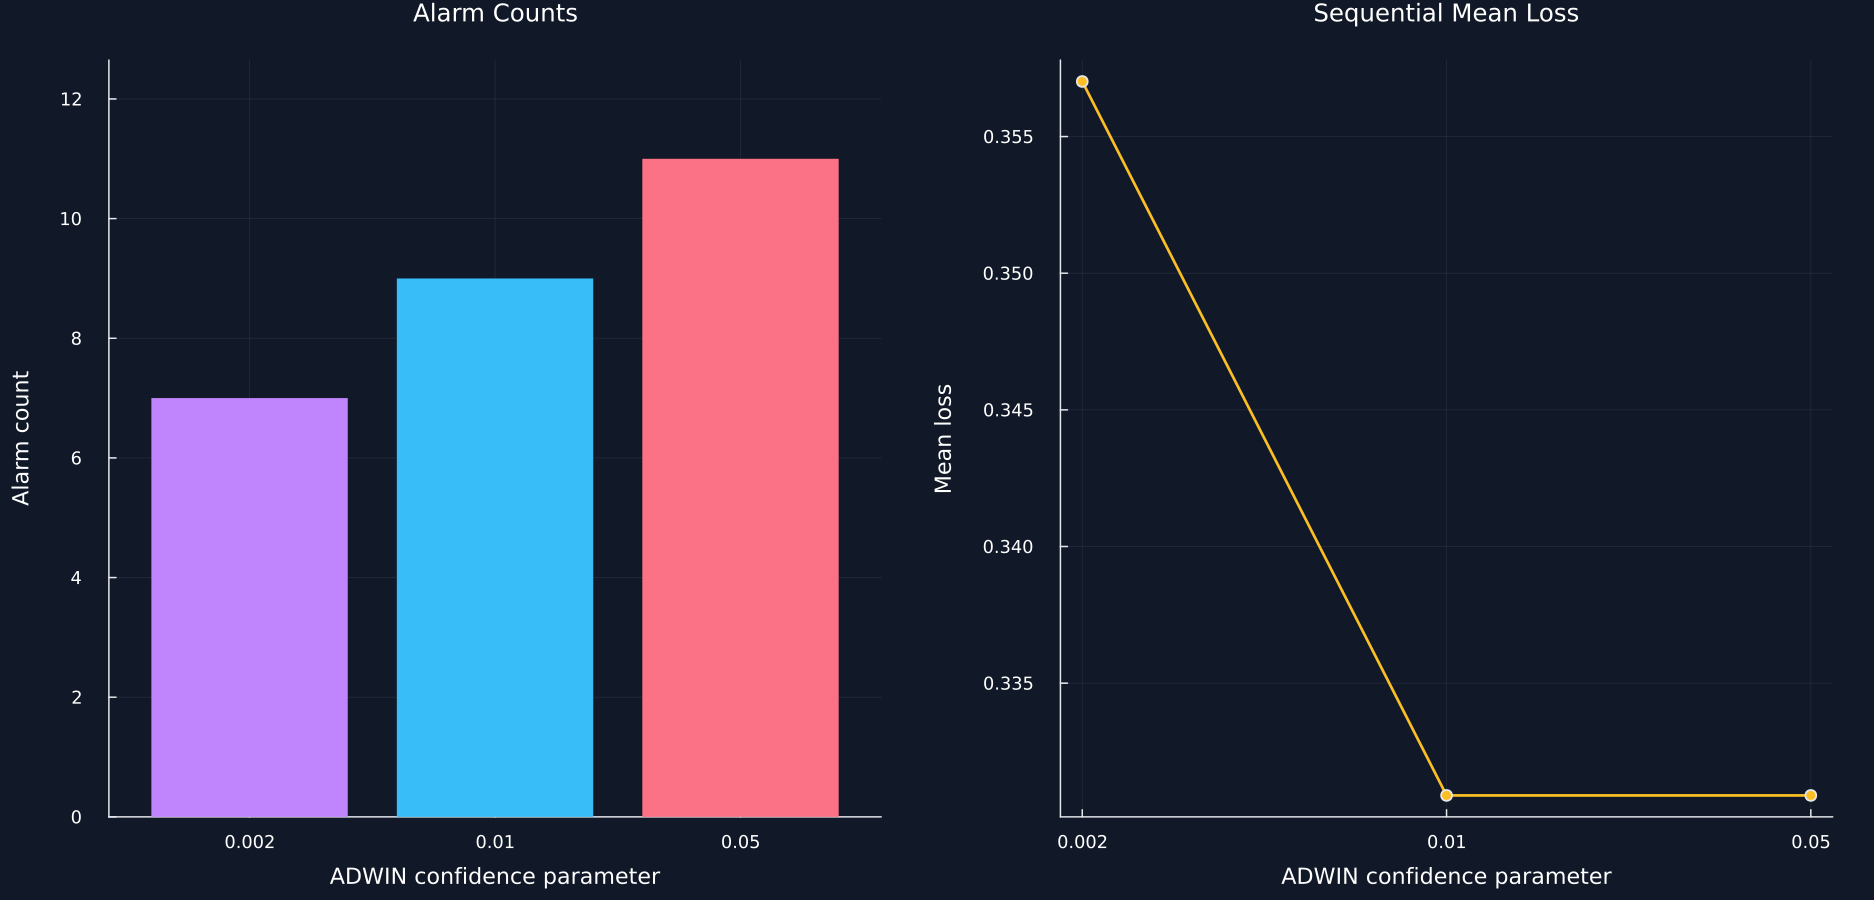

In [4]:
sensitivity_rows = NamedTuple[]
for delta in [.002,.01,.05]
    result = run_policy(features,targets;delta)
    save_policy(result,"sensitivity_"*replace(string(delta),"."=>"_"))
    losses = result.losses[min_samples+1:end]
    push!(sensitivity_rows,(delta=delta,alarms=length(result.alarm_indices),refits=length(result.refit_indices)-1,mistakes=Int(sum(losses)),mean_loss=mean(losses),accuracy=1-mean(losses)))
end
sensitivity = DataFrame(sensitivity_rows)
rename!(sensitivity,["ADWIN confidence parameter","Alarms","Refits after initialization","Mistakes","Mean loss","Accuracy"])
table(sensitivity,"delta_sensitivity","Predeclared sensitivity of alarms and loss to the ADWIN confidence parameter.")
save_data(sensitivity,paths,"delta_sensitivity");
labels = [@sprintf("%g",value) for value in sensitivity[!,1]]
p1 = bar(1:3,sensitivity.Alarms;xticks=(1:3,labels),color=[violet,palette.cyan,palette.rose],linealpha=0,label=false,xlabel="ADWIN confidence parameter",ylabel="Alarm count",title="Alarm Counts",ylims=(0,1.15maximum(sensitivity.Alarms)))
p2 = plot(1:3,sensitivity[!,"Mean loss"];xticks=(1:3,labels),color=palette.amber,marker=:circle,linewidth=1.8,label=false,xlabel="ADWIN confidence parameter",ylabel="Mean loss",title="Sequential Mean Loss")
save_figure(plot(p1,p2;layout=(1,2),size=(1250,600),left_margin=6Plots.mm),paths,"delta_sensitivity")
@assert sensitivity.Alarms==sensitivity[!,"Refits after initialization"]
@assert all(0 .<= sensitivity[!,"Mean loss"] .<= 1)


## What the Comparison Can and Cannot Show

The fixed public sample shows that the three predeclared policies can produce different loss paths and refit counts. It does not establish that one policy will remain better in another asset, period, target, cost structure, or model family. The comparison contains no trading position, return, transaction cost, or causal intervention. The observed loss differences are descriptive results for one sequential classification task.

In [5]:
table(DataFrame("Question" => ["What is compared?", "What does an ADWIN alarm mean?", "What does a refit do?", "What does the public sample establish?", "How is sensitivity used?"],"Permitted conclusion" => ["Prediction mistakes under three fixed refit policies", "Evidence of a change in the bounded loss stream", "Changes later predictions after observed data are added", "A reproducible description of this task and period", "Reports fixed alternative confidence parameters"],"Excluded conclusion" => ["Investment performance", "Proof of an economic cause", "Changes the prediction on the alarm date", "Universal forecasting superiority", "Selects the best setting after observing outcomes"]),"policy_interpretation_limits","Interpretation boundaries for the sequential policy comparison.","tab:chapter14-policy-interpretation-limits")
@assert length(evaluation_dates)==7235
@assert length(static.refit_indices)==1
@assert all(isfinite,Matrix(policy_summary[:,["Mean loss","Accuracy","Large move precision","Large move recall"]]))
@assert all(result->all(record->record.last_position-record.first_position+1==756,result.models),policy_outputs)


Row,Question,Permitted conclusion,Excluded conclusion
,String,String,String
1,What is compared?,Prediction mistakes under three fixed refit policies,Investment performance
2,What does an ADWIN alarm mean?,Evidence of a change in the bounded loss stream,Proof of an economic cause
3,What does a refit do?,Changes later predictions after observed data are added,Changes the prediction on the alarm date
4,What does the public sample establish?,A reproducible description of this task and period,Universal forecasting superiority
5,How is sensitivity used?,Reports fixed alternative confidence parameters,Selects the best setting after observing outcomes
